In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style("whitegrid")

df_fe = pd.read_csv("../data/processed/housing_features.csv")
print(df_fe.shape)   # should be (250000, ...) with the new columns included

(250000, 39)


# Price & Size Analysis

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style("whitegrid")

#### 1.	What is the distribution of property prices?

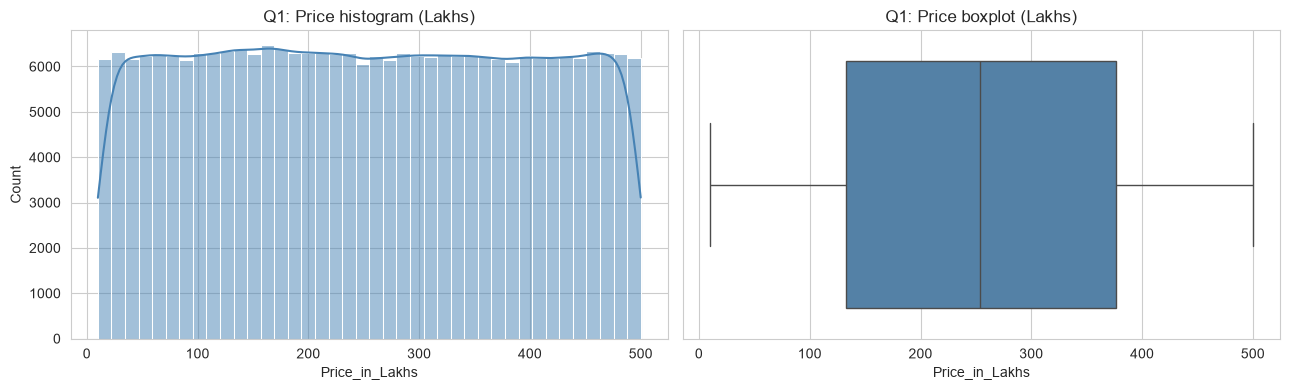

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_fe["Price_in_Lakhs"], bins=40, kde=True, color="steelblue", ax=ax[0])
ax[0].set_title("Q1: Price histogram (Lakhs)")
sns.boxplot(x=df_fe["Price_in_Lakhs"], color="steelblue", ax=ax[1])
ax[1].set_title("Q1: Price boxplot (Lakhs)")
plt.tight_layout()
plt.show()

#### 2.	What is the distribution of property sizes?

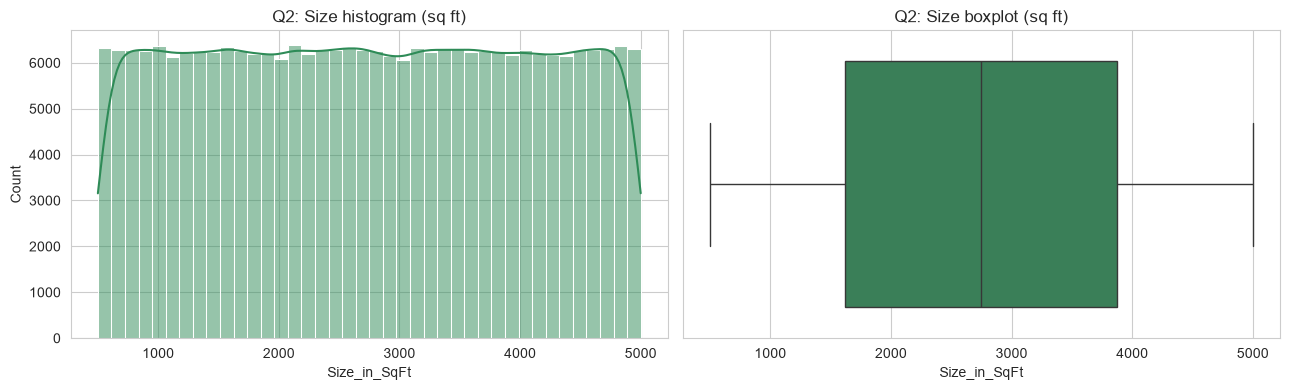

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_fe["Size_in_SqFt"], bins=40, kde=True, color="seagreen", ax=ax[0])
ax[0].set_title("Q2: Size histogram (sq ft)")
sns.boxplot(x=df_fe["Size_in_SqFt"], color="seagreen", ax=ax[1])
ax[1].set_title("Q2: Size boxplot (sq ft)")
plt.tight_layout()
plt.show()

#### 3.	How does price per sq ft vary by property type?

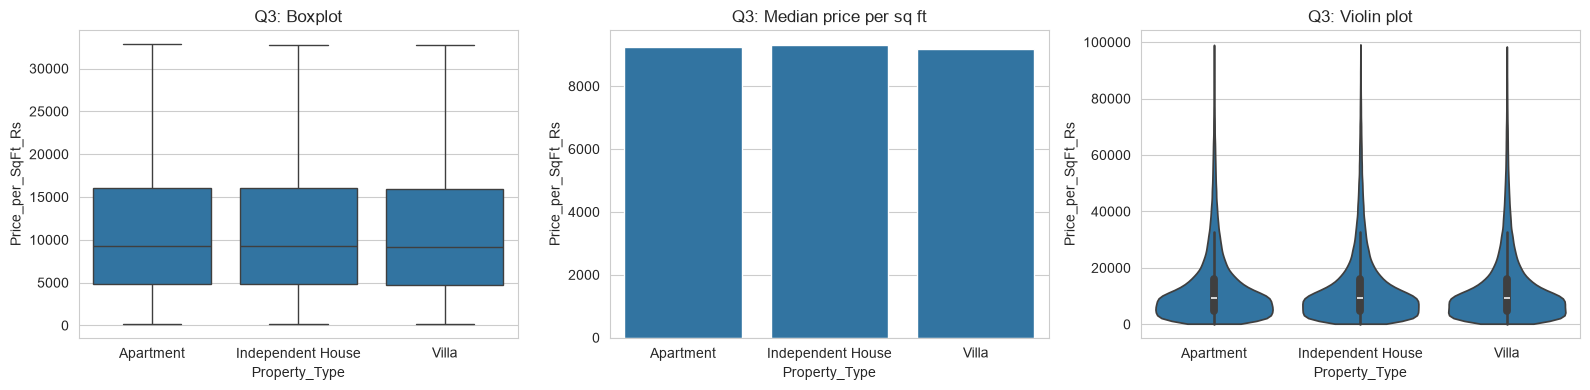

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df_fe, x="Property_Type", y="Price_per_SqFt_Rs", showfliers=False, ax=ax[0])
ax[0].set_title("Q3: Boxplot")
sns.barplot(data=df_fe, x="Property_Type", y="Price_per_SqFt_Rs", estimator="median", errorbar=None, ax=ax[1])
ax[1].set_title("Q3: Median price per sq ft")
sns.violinplot(data=df_fe, x="Property_Type", y="Price_per_SqFt_Rs", cut=0, ax=ax[2])
ax[2].set_title("Q3: Violin plot")
plt.tight_layout()
plt.show()

#### 4.	Is there a relationship between property size and price?



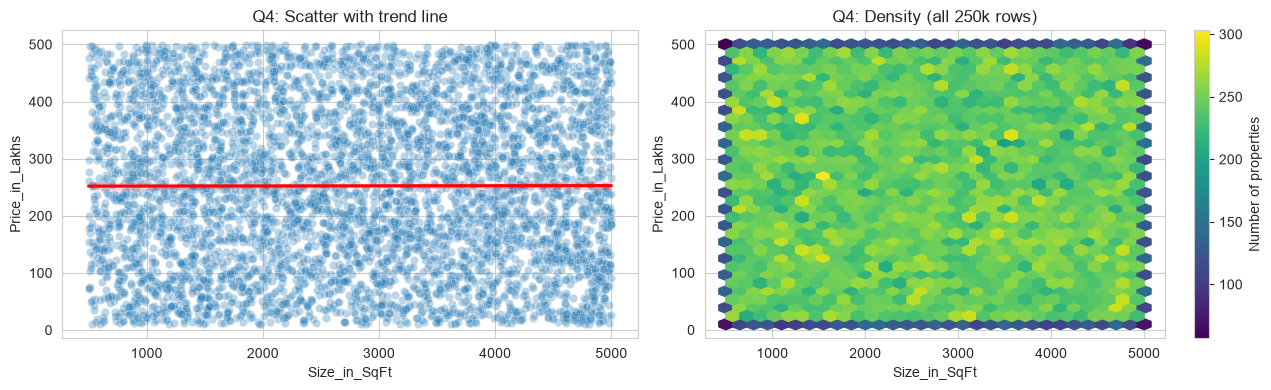

Correlation: -0.003


In [6]:
sample = df_fe.sample(5000, random_state=42)   # sample keeps the scatter readable
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.3, ax=ax[0])
sns.regplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", scatter=False, color="red", ax=ax[0])
ax[0].set_title("Q4: Scatter with trend line")
hb = ax[1].hexbin(df_fe["Size_in_SqFt"], df_fe["Price_in_Lakhs"], gridsize=30, cmap="viridis")
fig.colorbar(hb, ax=ax[1], label="Number of properties")
ax[1].set_title("Q4: Density (all 250k rows)")
ax[1].set_xlabel("Size_in_SqFt"); ax[1].set_ylabel("Price_in_Lakhs")
plt.tight_layout()
plt.show()
print("Correlation:", round(df_fe["Size_in_SqFt"].corr(df_fe["Price_in_Lakhs"]), 3))

#### 5.	Are there any outliers in price per sq ft or property size?

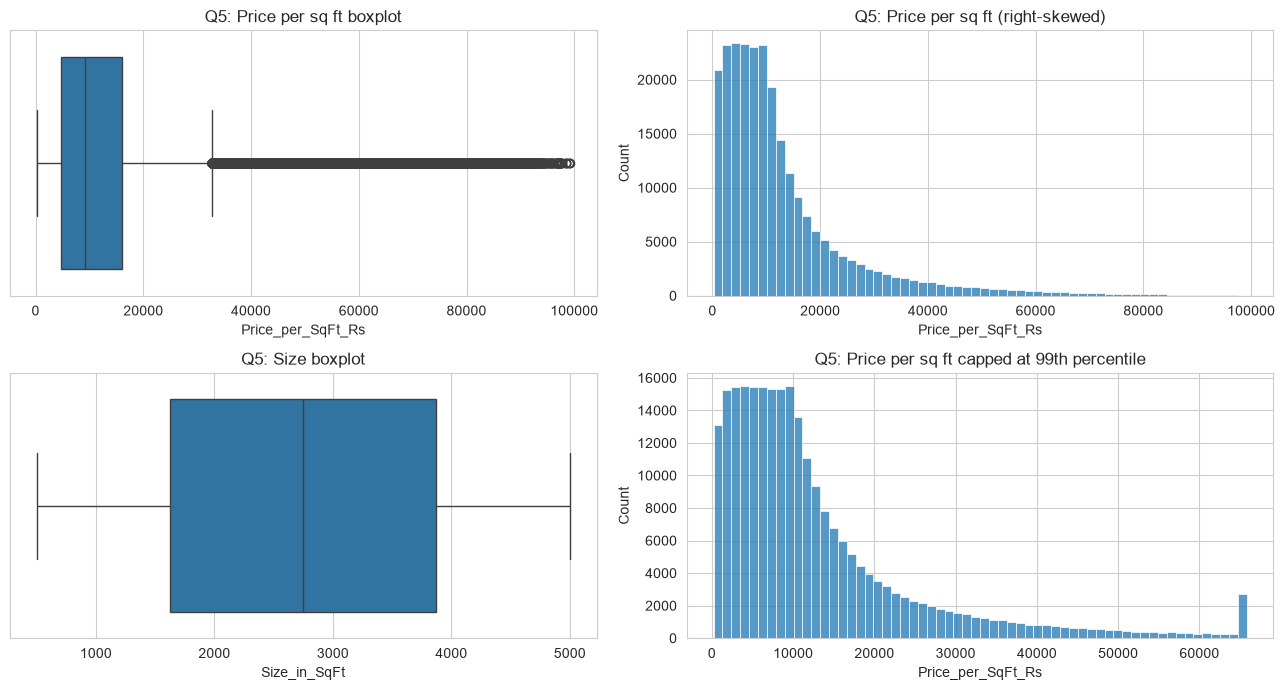

Price_per_SqFt_Rs: 19723 outliers (7.9%)
Size_in_SqFt: 0 outliers (0.0%)


In [7]:
cap = df_fe["Price_per_SqFt_Rs"].quantile(0.99)
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
sns.boxplot(x=df_fe["Price_per_SqFt_Rs"], ax=ax[0, 0]);  ax[0, 0].set_title("Q5: Price per sq ft boxplot")
sns.histplot(df_fe["Price_per_SqFt_Rs"], bins=60, ax=ax[0, 1]);  ax[0, 1].set_title("Q5: Price per sq ft (right-skewed)")
sns.boxplot(x=df_fe["Size_in_SqFt"], ax=ax[1, 0]);  ax[1, 0].set_title("Q5: Size boxplot")
sns.histplot(df_fe["Price_per_SqFt_Rs"].clip(upper=cap), bins=60, ax=ax[1, 1])
ax[1, 1].set_title("Q5: Price per sq ft capped at 99th percentile")
plt.tight_layout()
plt.show()

for c in ["Price_per_SqFt_Rs", "Size_in_SqFt"]:
    q1, q3 = df_fe[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n = ((df_fe[c] < q1 - 1.5 * iqr) | (df_fe[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c}: {n} outliers ({n / len(df_fe):.1%})")

# Location-based Analysis

#### 6.	What is the average price per sq ft by state?

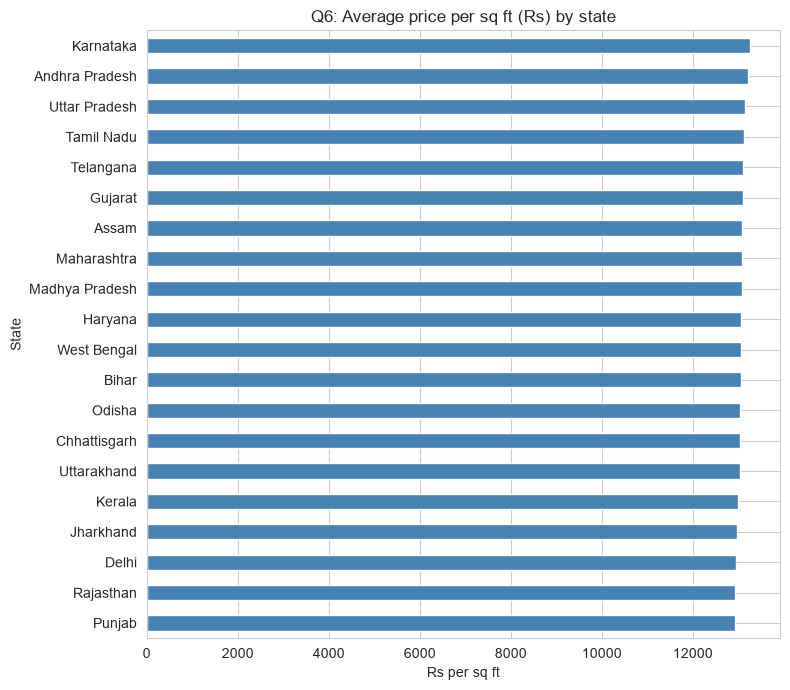

State
Karnataka         13252.0
Andhra Pradesh    13202.0
Uttar Pradesh     13143.0
Tamil Nadu        13132.0
Telangana         13093.0
Gujarat           13091.0
Assam             13084.0
Maharashtra       13070.0
Madhya Pradesh    13069.0
Haryana           13069.0
West Bengal       13061.0
Bihar             13051.0
Odisha            13033.0
Uttarakhand       13027.0
Chhattisgarh      13027.0
Kerala            12982.0
Jharkhand         12975.0
Delhi             12941.0
Rajasthan         12932.0
Punjab            12931.0
Name: Price_per_SqFt_Rs, dtype: float64


In [8]:
q6 = df_fe.groupby("State")["Price_per_SqFt_Rs"].mean().sort_values()
plt.figure(figsize=(8, 7))
q6.plot(kind="barh", color="steelblue")
plt.title("Q6: Average price per sq ft (Rs) by state")
plt.xlabel("Rs per sq ft")
plt.tight_layout()
plt.show()
print(q6.round(0).sort_values(ascending=False))

#### 7.	What is the average property price by city?

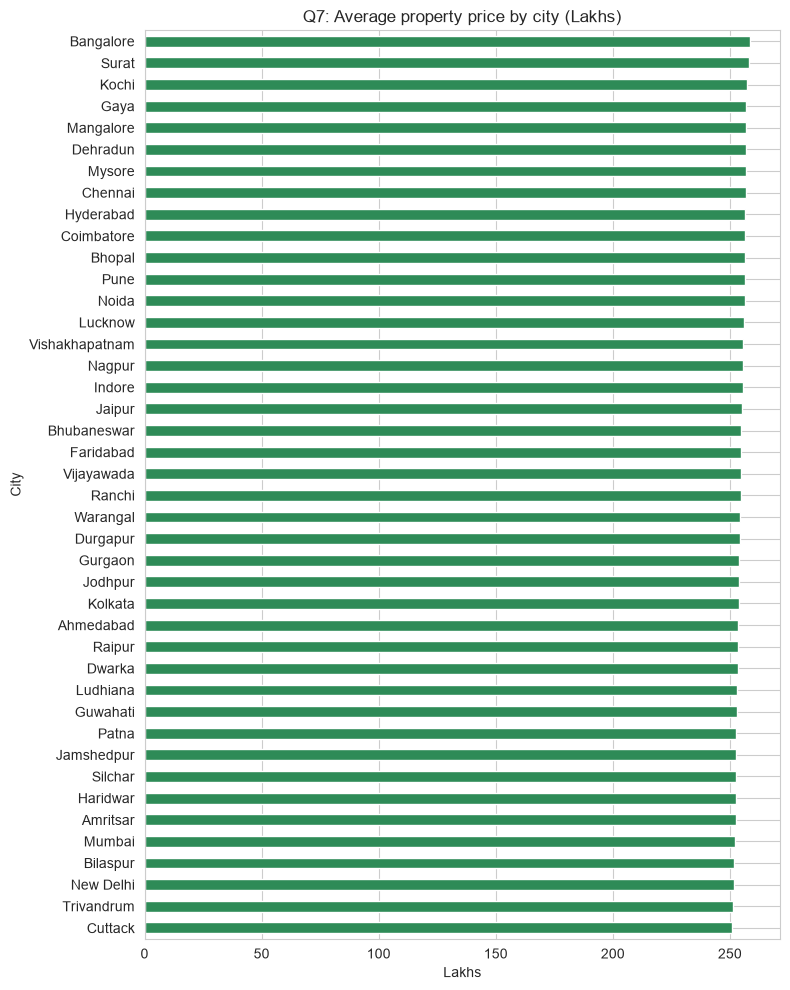

City
Bangalore    258.5
Surat        258.1
Kochi        257.4
Gaya         257.1
Mangalore    256.9
Dehradun     256.9
Mysore       256.8
Chennai      256.8
Hyderabad    256.6
Pune         256.5
Name: Price_in_Lakhs, dtype: float64


In [9]:
q7 = df_fe.groupby("City")["Price_in_Lakhs"].mean().sort_values()
plt.figure(figsize=(8, 10))
q7.plot(kind="barh", color="seagreen")
plt.title("Q7: Average property price by city (Lakhs)")
plt.xlabel("Lakhs")
plt.tight_layout()
plt.show()
print(q7.round(1).sort_values(ascending=False).head(10))

#### 8.	What is the median age of properties by locality?

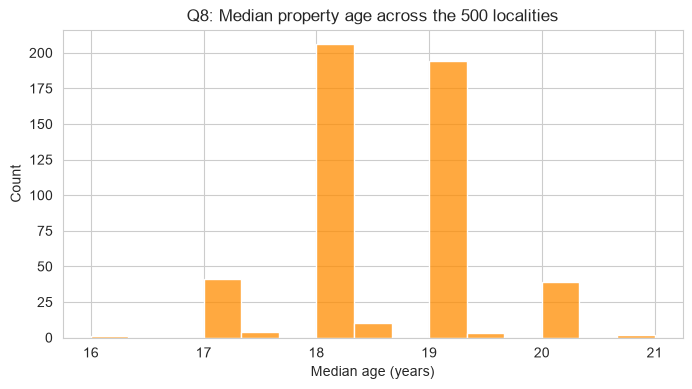

Youngest localities:
 Locality
Locality_443    16.0
Locality_92     17.0
Locality_60     17.0
Locality_10     17.0
Locality_13     17.0
Name: Age_of_Property, dtype: float64
Oldest localities:
 Locality
Locality_499    20.0
Locality_99     20.0
Locality_127    20.0
Locality_403    21.0
Locality_72     21.0
Name: Age_of_Property, dtype: float64


In [10]:
q8 = df_fe.groupby("Locality")["Age_of_Property"].median().sort_values()
plt.figure(figsize=(8, 4))
sns.histplot(q8, bins=15, color="darkorange")
plt.title("Q8: Median property age across the 500 localities")
plt.xlabel("Median age (years)")
plt.show()
print("Youngest localities:\n", q8.head(5))
print("Oldest localities:\n", q8.tail(5))

#### 9.	How is BHK distributed across cities?

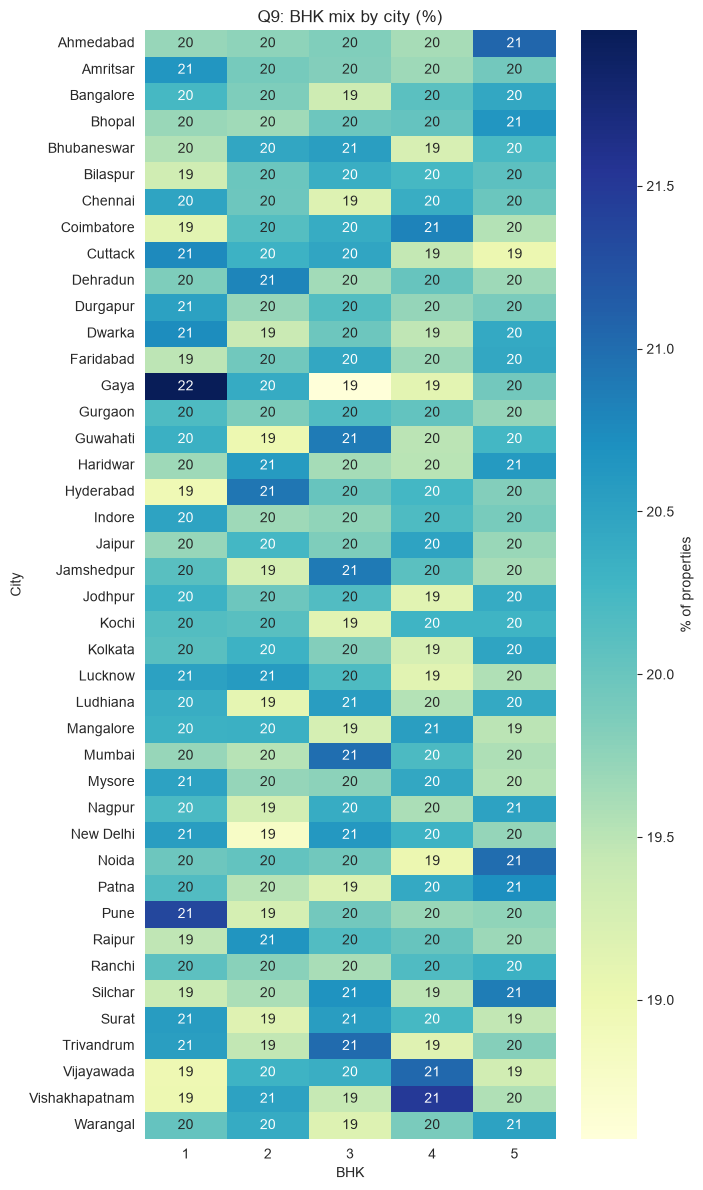

In [11]:
bhk_city = pd.crosstab(df_fe["City"], df_fe["BHK"], normalize="index") * 100
plt.figure(figsize=(7, 12))
sns.heatmap(bhk_city, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of properties"})
plt.title("Q9: BHK mix by city (%)")
plt.tight_layout()
plt.show()

#### 10.	What are the price trends for the top 5 most expensive localities?

Locality
Locality_395    275.4
Locality_366    273.4
Locality_497    270.0
Locality_360    269.8
Locality_203    269.0
Name: Price_in_Lakhs, dtype: float64


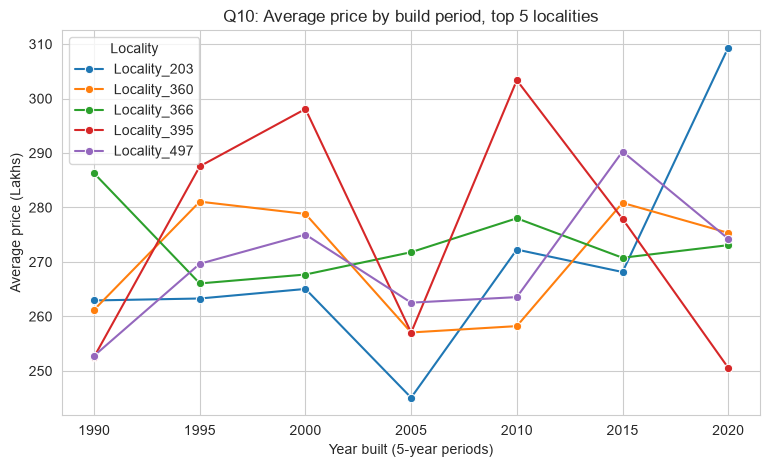

In [12]:
top5 = df_fe.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5)
print(top5.round(1))

t = df_fe[df_fe["Locality"].isin(top5.index)].copy()
t["Build_Period"] = (t["Year_Built"] // 5) * 5            # group years into 5-year periods
trend = t.groupby(["Build_Period", "Locality"])["Price_in_Lakhs"].mean().reset_index()

plt.figure(figsize=(9, 5))
sns.lineplot(data=trend, x="Build_Period", y="Price_in_Lakhs", hue="Locality", marker="o")
plt.title("Q10: Average price by build period, top 5 localities")
plt.xlabel("Year built (5-year periods)")
plt.ylabel("Average price (Lakhs)")
plt.show()

# Feature Relationship & Correlation

#### 11.	How are numeric features correlated with each other?

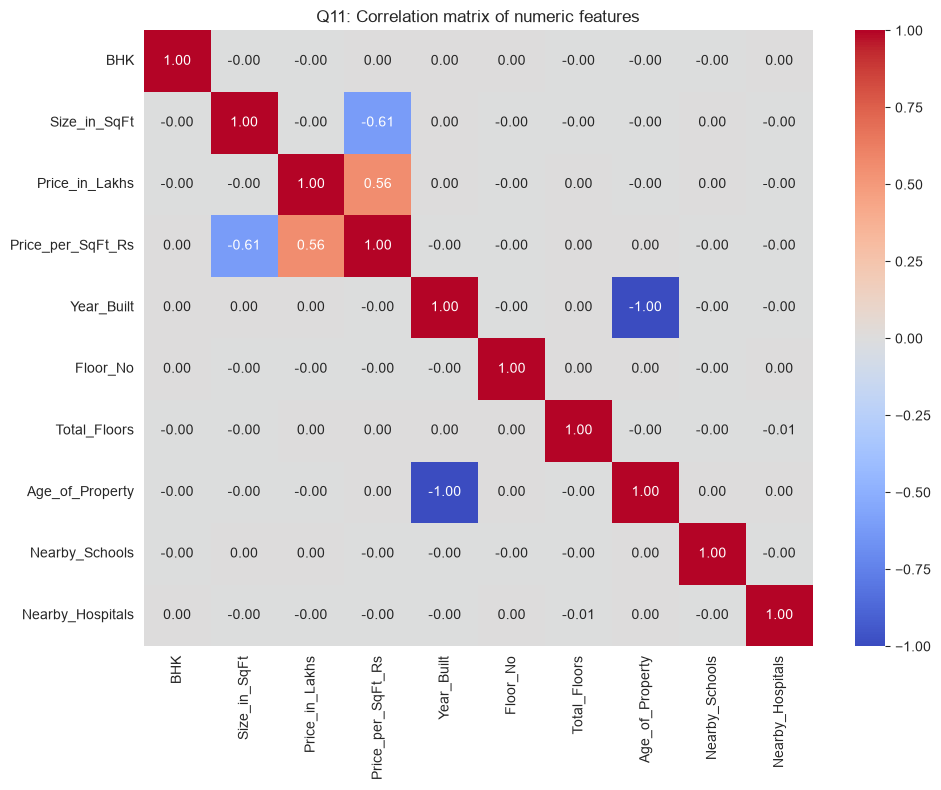

In [13]:
num_cols = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_Rs", "Year_Built",
            "Floor_No", "Total_Floors", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals"]
corr = df_fe[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Q11: Correlation matrix of numeric features")
plt.tight_layout()
plt.show()

#### 12.	How do nearby schools relate to price per sq ft?

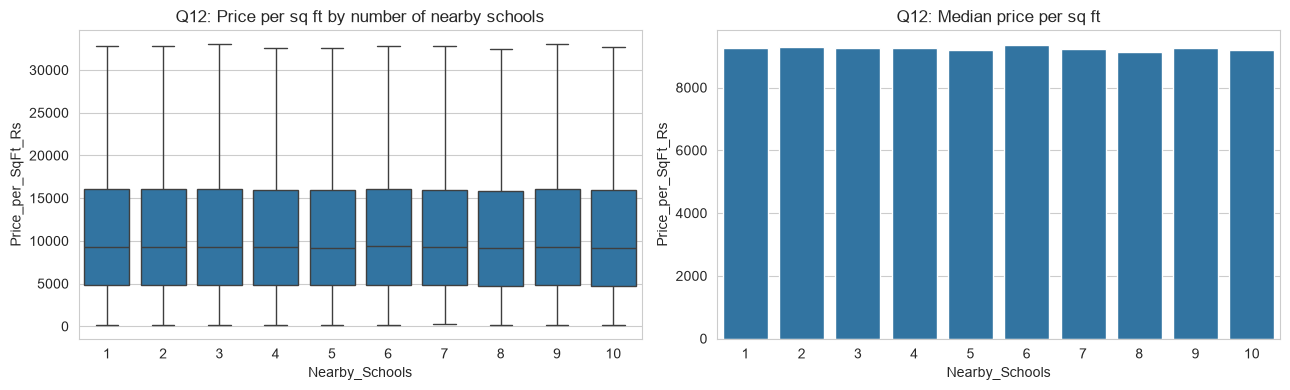

Correlation: -0.0


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df_fe, x="Nearby_Schools", y="Price_per_SqFt_Rs", showfliers=False, ax=ax[0])
ax[0].set_title("Q12: Price per sq ft by number of nearby schools")
sns.barplot(data=df_fe, x="Nearby_Schools", y="Price_per_SqFt_Rs", estimator="median", errorbar=None, ax=ax[1])
ax[1].set_title("Q12: Median price per sq ft")
plt.tight_layout()
plt.show()
print("Correlation:", round(df_fe["Nearby_Schools"].corr(df_fe["Price_per_SqFt_Rs"]), 3))

####  13.	How do nearby hospitals relate to price per sq ft?

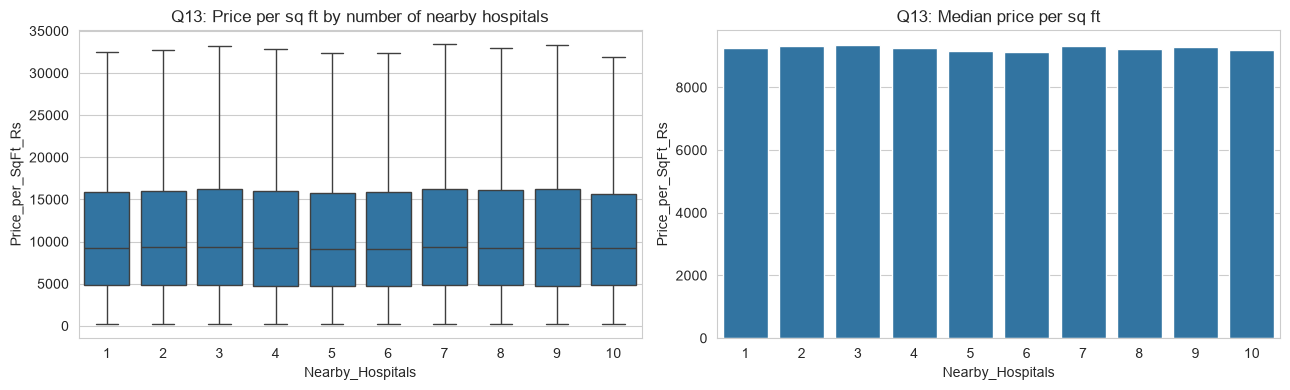

Correlation: -0.0


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df_fe, x="Nearby_Hospitals", y="Price_per_SqFt_Rs", showfliers=False, ax=ax[0])
ax[0].set_title("Q13: Price per sq ft by number of nearby hospitals")
sns.barplot(data=df_fe, x="Nearby_Hospitals", y="Price_per_SqFt_Rs", estimator="median", errorbar=None, ax=ax[1])
ax[1].set_title("Q13: Median price per sq ft")
plt.tight_layout()
plt.show()
print("Correlation:", round(df_fe["Nearby_Hospitals"].corr(df_fe["Price_per_SqFt_Rs"]), 3))

#### 14.	How does price vary by furnished status?

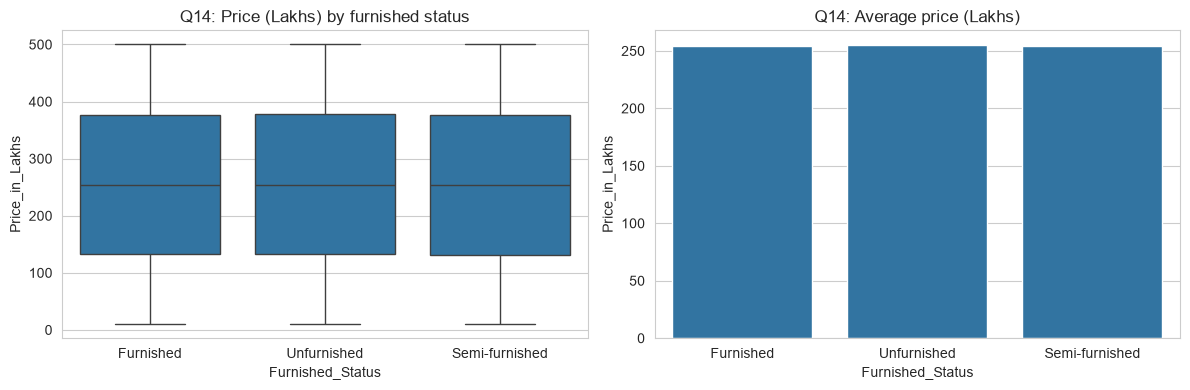

                   mean  median
Furnished_Status               
Furnished         254.4   253.6
Semi-furnished    254.3   253.8
Unfurnished       255.0   254.2


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df_fe, x="Furnished_Status", y="Price_in_Lakhs", ax=ax[0])
ax[0].set_title("Q14: Price (Lakhs) by furnished status")
sns.barplot(data=df_fe, x="Furnished_Status", y="Price_in_Lakhs", errorbar=None, ax=ax[1])
ax[1].set_title("Q14: Average price (Lakhs)")
plt.tight_layout()
plt.show()
print(df_fe.groupby("Furnished_Status")["Price_in_Lakhs"].agg(["mean", "median"]).round(1))

#### 15.	How does price per sq ft vary by property facing direction?

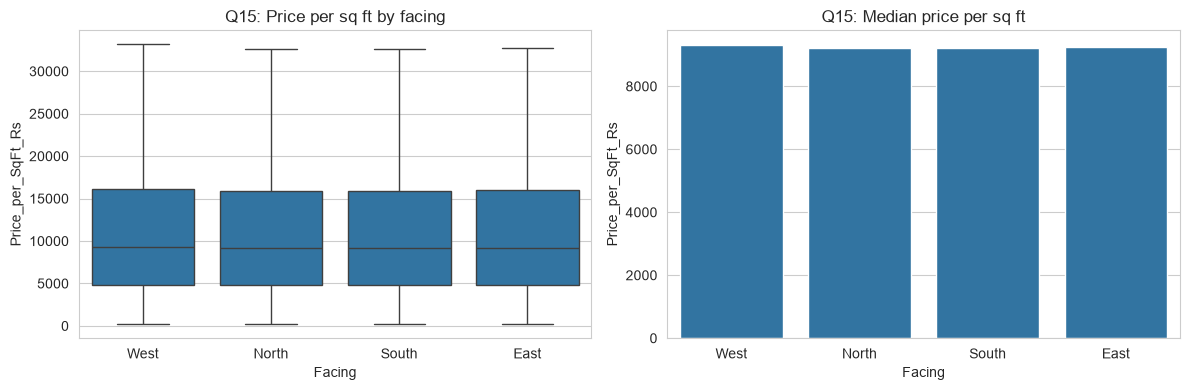

           mean  median
Facing                 
East    13024.0  9234.0
North   13025.0  9219.0
South   13044.0  9225.0
West    13140.0  9308.0


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df_fe, x="Facing", y="Price_per_SqFt_Rs", showfliers=False, ax=ax[0])
ax[0].set_title("Q15: Price per sq ft by facing")
sns.barplot(data=df_fe, x="Facing", y="Price_per_SqFt_Rs", estimator="median", errorbar=None, ax=ax[1])
ax[1].set_title("Q15: Median price per sq ft")
plt.tight_layout()
plt.show()
print(df_fe.groupby("Facing")["Price_per_SqFt_Rs"].agg(["mean", "median"]).round(0))

# Investment / Amenities / Ownership Analysis

#### 16.	How many properties belong to each owner type?

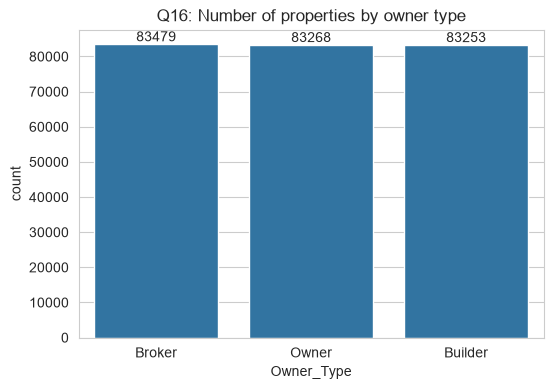

Owner_Type
Broker     83479
Owner      83268
Builder    83253
Name: count, dtype: int64


In [18]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_fe, x="Owner_Type", order=df_fe["Owner_Type"].value_counts().index)
ax.bar_label(ax.containers[0])
plt.title("Q16: Number of properties by owner type")
plt.show()
print(df_fe["Owner_Type"].value_counts())

#### 17.	How many properties are available under each availability status?

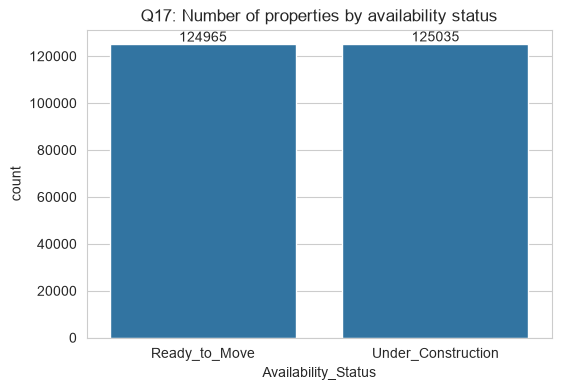

Availability_Status
Under_Construction    125035
Ready_to_Move         124965
Name: count, dtype: int64


In [19]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_fe, x="Availability_Status")
ax.bar_label(ax.containers[0])
plt.title("Q17: Number of properties by availability status")
plt.show()
print(df_fe["Availability_Status"].value_counts())

#### 18.	Does parking space affect property price?

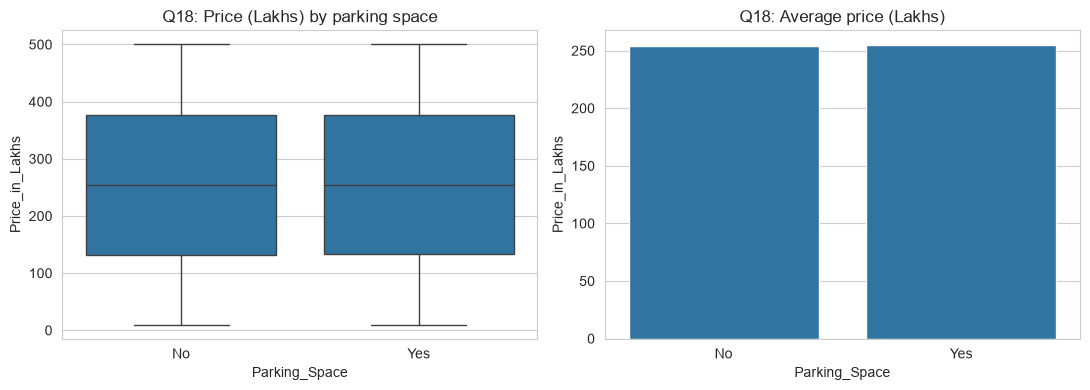

                mean  median
Parking_Space               
No             254.4   253.4
Yes            254.7   254.4


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df_fe, x="Parking_Space", y="Price_in_Lakhs", ax=ax[0])
ax[0].set_title("Q18: Price (Lakhs) by parking space")
sns.barplot(data=df_fe, x="Parking_Space", y="Price_in_Lakhs", errorbar=None, ax=ax[1])
ax[1].set_title("Q18: Average price (Lakhs)")
plt.tight_layout()
plt.show()
print(df_fe.groupby("Parking_Space")["Price_in_Lakhs"].agg(["mean", "median"]).round(1))

#### 19.	How do amenities affect price per sq ft?

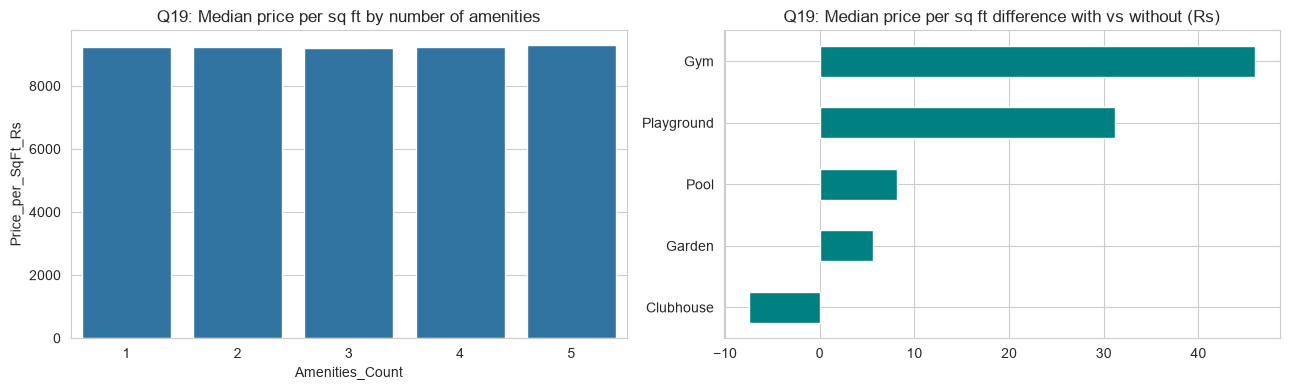

                    mean  median
Amenities_Count                 
1                13015.0  9240.0
2                13059.0  9242.0
3                13044.0  9207.0
4                13071.0  9250.0
5                13102.0  9294.0


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=df_fe, x="Amenities_Count", y="Price_per_SqFt_Rs", estimator="median", errorbar=None, ax=ax[0])
ax[0].set_title("Q19: Median price per sq ft by number of amenities")

amen = df_fe["Amenities"].str.get_dummies(sep=", ")
diff = {a: df_fe.loc[amen[a] == 1, "Price_per_SqFt_Rs"].median()
           - df_fe.loc[amen[a] == 0, "Price_per_SqFt_Rs"].median() for a in amen}
pd.Series(diff).sort_values().plot(kind="barh", ax=ax[1], color="teal")
ax[1].set_title("Q19: Median price per sq ft difference with vs without (Rs)")
plt.tight_layout()
plt.show()
print(df_fe.groupby("Amenities_Count")["Price_per_SqFt_Rs"].agg(["mean", "median"]).round(0))

#### 20.	How does public transport accessibility relate to price per sq ft or investment potential?

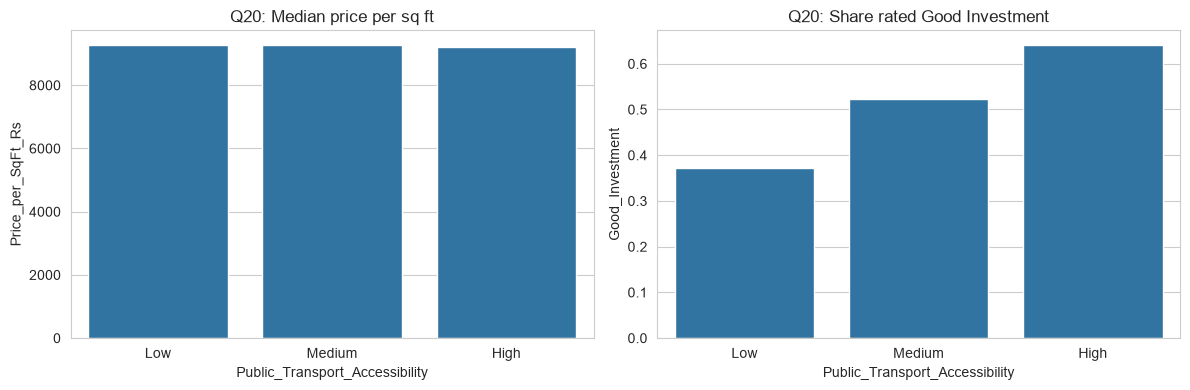

Public_Transport_Accessibility
High      9205.0
Low       9265.0
Medium    9269.0
Name: Price_per_SqFt_Rs, dtype: float64
Public_Transport_Accessibility
High      0.641
Low       0.371
Medium    0.523
Name: Good_Investment, dtype: float64


In [22]:
order = ["Low", "Medium", "High"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df_fe, x="Public_Transport_Accessibility", y="Price_per_SqFt_Rs",
            order=order, estimator="median", errorbar=None, ax=ax[0])
ax[0].set_title("Q20: Median price per sq ft")
sns.barplot(data=df_fe, x="Public_Transport_Accessibility", y="Good_Investment",
            order=order, errorbar=None, ax=ax[1])
ax[1].set_title("Q20: Share rated Good Investment")
plt.tight_layout()
plt.show()
print(df_fe.groupby("Public_Transport_Accessibility")["Price_per_SqFt_Rs"].median().round(0))
print(df_fe.groupby("Public_Transport_Accessibility")["Good_Investment"].mean().round(3))